In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
img = cv2.imread("sift1.jpg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
img = img.astype(np.float32)

output_img = img.copy()

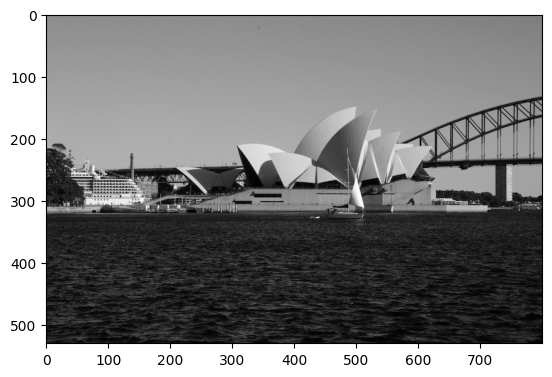

In [3]:
plt.imshow(img, cmap="grey")

In [4]:
# creating scale space
s = 3
num_images = s + 3
k = 2 ** (1/s)
octave_wise_sigmas = {}
s_initial = 1.6

for octave_num in range(1, 7):
    curr_octave_sigmas = []
    for i in range(num_images):
        curr_octave_sigmas.append((2**(octave_num - 1)) * (k**i) * s_initial)
    octave_wise_sigmas[f"octave_{octave_num}"] = curr_octave_sigmas

In [5]:
octave_wise_sigmas

{'octave_1': [1.6,
  2.015873679831797,
  2.5398416831491195,
  3.2,
  4.031747359663594,
  5.079683366298239],
 'octave_2': [3.2,
  4.031747359663594,
  5.079683366298239,
  6.4,
  8.063494719327188,
  10.159366732596478],
 'octave_3': [6.4,
  8.063494719327188,
  10.159366732596478,
  12.8,
  16.126989438654377,
  20.318733465192956],
 'octave_4': [12.8,
  16.126989438654377,
  20.318733465192956,
  25.6,
  32.253978877308754,
  40.63746693038591],
 'octave_5': [25.6,
  32.253978877308754,
  40.63746693038591,
  51.2,
  64.50795775461751,
  81.27493386077182],
 'octave_6': [51.2,
  64.50795775461751,
  81.27493386077182,
  102.4,
  129.01591550923501,
  162.54986772154365]}

In [6]:
def get_del_sigma(sigma1, sigma2):
    return np.sqrt(sigma2**2 - sigma1**2)

def create_dogs_octave(octave_sigmas, img):
    gk_applied_imgs = [img]
    for k in range(1, len(octave_sigmas)):
        del_sigma = get_del_sigma(octave_sigmas[k - 1], octave_sigmas[k])
        kernel_size = int(2*np.ceil(3*del_sigma)+1)
        gk = gaussian_kernel(kernel_size, del_sigma)
        o_gk_img = gk_applied_imgs[-1].copy()

        K = gk.shape[0]
        for i in range(0, gk_applied_imgs[-1].shape[0] - K + 1):
            for j in range(0, gk_applied_imgs[-1].shape[1] - K + 1):
                img_slice = gk_applied_imgs[-1][i:i+K, j:j+K]
                o_gk_img[i + K//2, j + K//2] = np.sum(gk * img_slice)

        gk_applied_imgs.append(o_gk_img)
    dogs = []
    for i in range(1, len(gk_applied_imgs)):
        dogs.append(gk_applied_imgs[i] - gk_applied_imgs[i-1])
    return dogs        

In [7]:
def gaussian_kernel(size, sigma):
    assert size % 2 == 1, "Kernel size must be odd"
    k = size // 2
    x, y = np.meshgrid(np.arange(-k, k + 1), np.arange(-k, k + 1))
    kernel = np.exp(-(x**2 + y**2) / (2 * sigma**2))
    kernel /= kernel.sum()
    return kernel.astype(np.float32)

In [8]:
dogs_octave = create_dogs_octave(octave_wise_sigmas["octave_3"], img)

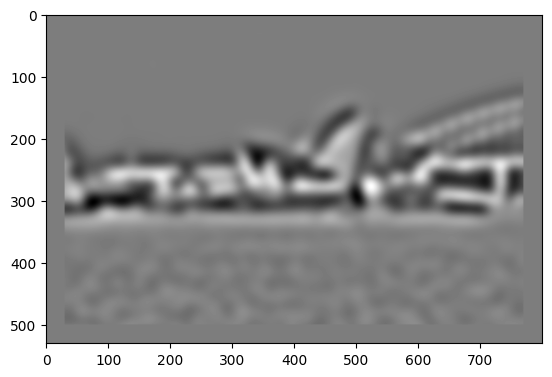

In [9]:
plt.imshow(dogs_octave[3], cmap="grey")

In [10]:
output_img = dogs_octave[3].copy()

In [11]:
len(dogs_octave)

5

In [12]:
def keypoint_check_condition(slice_3d_img):
    assert slice_3d_img.shape == (3,3,3)
    x = slice_3d_img.flatten()
    center_pxl_index = x.shape[0]//2
    center_pxl_val = x[center_pxl_index] # getting the center pxl value in the 3d slice
    y = np.delete(x, center_pxl_index)
    if np.all(center_pxl_val > y) or np.all(center_pxl_val < y):
        return True
    else:
        return False
        
# skip first and last dog
kernel_dim = 3
keypoints_curr_octave = []
for k in range(1, len(dogs_octave)-1): 
    dogs_3d = np.stack([dogs_octave[k-1], dogs_octave[k], dogs_octave[k+1]])
    
    for i in range(dogs_3d.shape[1]-kernel_dim):
        for j in range(dogs_3d.shape[2]-kernel_dim):
            dogs_3d_slice = dogs_3d[:, i:i+kernel_dim, j:j+kernel_dim]
            if keypoint_check_condition(dogs_3d_slice) and abs(dogs_octave[k][i+1, j+1]) < 12:
                output_img = cv2.circle(output_img, (j+kernel_dim//2, i+kernel_dim//2), 5,  (255, 0, 0), 1)

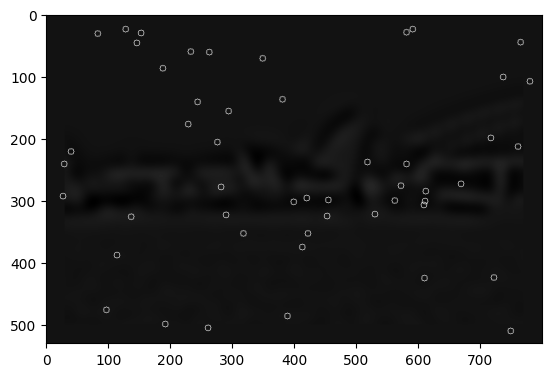

In [13]:
plt.imshow(output_img, cmap="grey")

In [14]:
def hessian_test(slice_3d_img):
    kernel_dim = 3
    for i in range(kernel_dim//2, img.shape[0] - kernel_dim):
        for j in range(kernel_dim//2, img.shape[1] - kernel_dim):
            img_slice = img[i:i+kernel_dim, j:j+kernel_dim]
    
            slice_center_row = img_slice[img_slice.shape[0]//2]
            del_square_i_x = slice_center_row[kernel_dim-1] - 2 * slice_center_row[kernel_dim//2] + slice_center_row[0]
    
            slice_center_col = img_slice[:, kernel_dim//2]
            del_square_i_y = slice_center_col[kernel_dim-1] - 2 * slice_center_col[kernel_dim//2] + slice_center_col[0]

            
    
            # output_img[i+kernel_dim//2, j+kernel_dim//2] = del_square_i_x + del_square_i_y

(3, 530, 800)